# Week 1, core 1: Your toolkit

This is an applied course: every week you will run code, change it, and read what it tells you. Before any machine learning, the tools have to work. This notebook makes sure they do, and it shows the small set of conventions that every later notebook follows, so that nothing in Week 6 looks unfamiliar.

Setting up an environment *is* part of the content of an applied AI course. If something fails today, that is normal; the fallback path (Google Colab) is built in, and the Week 1 discussion board is for exactly these problems.

## What you will learn

- How a notebook runs: cells, the kernel, and why *Restart kernel and run all* is the test that your work is correct.
- What the setup cell at the top of every notebook does, line by line.
- How data gets to you: the one download cell you will see all semester.
- What the course's AI-assistant policy allows, and what the two callouts `AI assistant: good use here` and `Write this yourself` mean.


In [1]:
# If this notebook is running on Google Colab, install the one package Colab doesn't ship with.
# This cell comes BEFORE the imports. "%pip" installs into the running kernel.
import sys
if "google.colab" in sys.modules:
    %pip install -q cartopy


In [2]:
# --- Setup: all imports, the seed, plot settings. The same block opens every notebook in this course. ---
import os
import random
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

seed = 42                      # one seed for the whole notebook; re-set it before any cell you re-run
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

plt.rcParams["figure.figsize"] = (8, 4)
plt.rcParams["font.size"] = 12
# Okabe–Ito: eight colorblind-safe colors as the default color cycle
plt.rcParams["axes.prop_cycle"] = plt.cycler(color=["#E69F00", "#56B4E9", "#009E73", "#F0E442",
                                                     "#0072B2", "#D55E00", "#CC79A7", "#000000"])


## Notebooks: cells, the kernel, and *Restart kernel and run all*

A notebook is a list of cells. Markdown cells (like this one) hold text; code cells hold Python. When you run a code cell, the code is sent to a **kernel**, a Python process that remembers every variable you have defined. The variables live in the kernel, not in the notebook file.

That memory is useful and dangerous. Useful: you can define `x` in one cell and plot it in the next. Dangerous: if you run cells out of order, or re-run a cell after changing an earlier one, the kernel's memory no longer matches what the notebook says. The cure is one habit, used before you submit anything and before you ask for help:

**Kernel → Restart kernel and run all cells.** If the notebook runs top to bottom without error, your work is reproducible. If it stops, the error is real and the line it stops on tells you where.


In [3]:
x = 3                      # the kernel now remembers x
print("x is", x)


x is 3


In [4]:
y = 2 * x                  # this cell depends on the one above having run
print("y is", y)


y is 6


> **Exercise.** Predict first: if you *Restart the kernel* (Kernel menu) and then run only the second of the two cells above, what happens? Write your prediction down, then try it. Afterwards, run *Restart kernel and run all cells* to put everything back.

You should see an error. Which error, and why, is the point of this section; the explanation is in the exercise solutions at the end of the notebook.

> **Check your understanding.** A classmate's notebook runs perfectly on their machine but fails at cell 3 on yours. Which single action tells you whether the problem is their notebook or your environment?


## Lines that are not Python: `%` and `!`

Two kinds of line appear in notebooks that are not Python. A line starting with `%` is a command to the notebook itself (a "magic"), and a line starting with `!` runs a command in your computer's shell. You saw one already: the very first cell uses `%pip install` to add a package on Colab. You will not write many of these; you only need to recognize them.


In [5]:
# A magic: where on disk this notebook is running, which is where the data/ folder will be created.
# The comment sits on its own line because a magic treats everything after it on the same line as arguments.
%pwd


'/Users/cristi/Dropbox/work/teaching/GEOL-ATMS_522/book/week01_ml_workflow'

In [6]:
# A magic: every variable the kernel currently remembers, with its type.
%whos


Variable   Type      Data/Info
------------------------------
nn         module    <module 'torch.nn' from '<...>es/torch/nn/__init__.py'>
np         module    <module 'numpy' from '/Us<...>kages/numpy/__init__.py'>
os         module    <module 'os' (frozen)>
pd         module    <module 'pandas' from '/U<...>ages/pandas/__init__.py'>
plt        module    <module 'matplotlib.pyplo<...>es/matplotlib/pyplot.py'>
random     module    <module 'random' from '/U<...>ib/python3.12/random.py'>
seed       int       42
sys        module    <module 'sys' (built-in)>
torch      module    <module 'torch' from '/Us<...>kages/torch/__init__.py'>
urllib     module    <module 'urllib' from '/U<...>3.12/urllib/__init__.py'>
x          int       3
y          int       6


## The setup cell, line by line

Every notebook in this course opens with the same block (scroll up to see it). Here is what each part does and why it is there.

- **Imports.** `numpy` for arrays, `pandas` for tables, `matplotlib` for figures, and `torch`, used from Week 4. Importing everything in one place means you always know what a name refers to.
- **The seed.** `random.seed(seed)`, `np.random.seed(seed)` and `torch.manual_seed(seed)` make the notebook's random choices repeatable: the same "random" numbers every time, so your result and ours agree. The seed is set once at the top, and **again at the top of any cell you are asked to re-run with a change**, so that the change you made is the only difference.
- **Plot settings.** A default figure size, a readable font size, and a set of eight colors (the Okabe–Ito palette) that can be told apart by readers with the common forms of color-vision deficiency.

The eight colors, in the order matplotlib will use them:


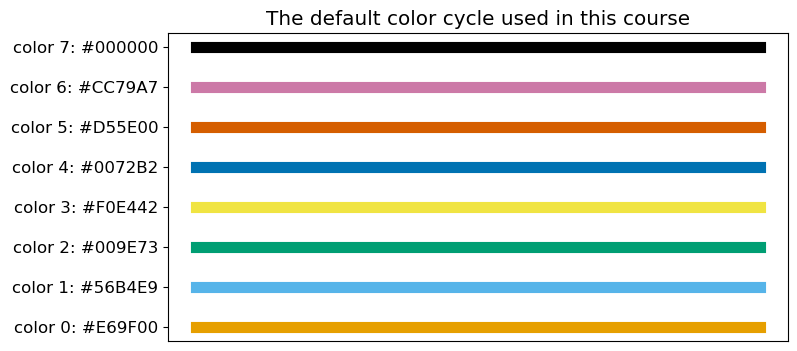

In [7]:
colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]

fig, ax = plt.subplots()
for i, color in enumerate(colors):
    ax.plot([0, 1], [i, i], linewidth=8, color=color)
ax.set_yticks(range(len(colors)))
ax.set_yticklabels([f"color {i}: {color}" for i, color in enumerate(colors)])   # each color's hex code
ax.set_xticks([])
ax.set_title("The default color cycle used in this course")
plt.show()


Eight horizontal bars, one per color in the course's default cycle; the first line of any multi-line plot will be orange, the second light blue, and so on.

> **Exercise.** Predict what the figure above looks like if the figure size is changed to `(4, 6)` (narrow and tall). Then change the line `plt.rcParams["figure.figsize"] = (8, 4)` in the setup cell, re-run the setup cell and the plot cell, and look. Put it back to `(8, 4)` afterwards and re-run both cells.

> **Check your understanding.** You change one number in a cell and re-run only that cell. Why does the course ask you to re-set the seed at the top of the cell first?


## How data gets to you: the download cell

You will never be handed a data file by email. Every lab and homework downloads what it needs with a cell of exactly this shape. It creates a folder called `data` next to the notebook, and downloads a file into it **only if the file is not already there**, so running the cell twice costs nothing and a file you placed there by hand is simply used.

The file below is the smallest piece of the CAMELS dataset you will meet properly in the lab: the names of 671 US river catchments.


In [8]:
data_dir = "data"                       # created next to this notebook; ignored by git
os.makedirs(data_dir, exist_ok=True)

url = "https://zenodo.org/records/15529996/files/camels_name.txt?download=1"
fname = os.path.join(data_dir, "camels_name.txt")

if not os.path.exists(fname):           # download once; a hand-placed file is simply used
    print("downloading", url)
    urllib.request.urlretrieve(url, fname)
else:
    print("already here:", fname)


already here: data/camels_name.txt


In [9]:
names = pd.read_csv(fname, sep=";", dtype={"gauge_id": str})   # the CAMELS files use ";" between columns
print(names.shape)                                               # (n_catchments, n_columns)
names.head()


(671, 3)


,gauge_id,huc_02,gauge_name
0,01013500,1,"Fish River near Fort Kent, Maine"
1,01022500,1,"Narraguagus River at Cherryfield, Maine"
2,01030500,1,"Mattawamkeag River near Mattawamkeag, Maine"
3,01031500,1,"Piscataquis River near Dover-Foxcroft, Maine"
4,01047000,1,"Carrabassett River near North Anson, Maine"


> **Exercise.** Predict what the download cell prints if you run it a second time. Then run it again.

> **Check your understanding.** You delete the `data` folder and run the download cell. What happens, and why is that the behavior we want?

> **Earth-science aside.** CAMELS stands for *Catchment Attributes and MEteorology for Large-sample Studies*: 671 catchments across the contiguous United States with decades of daily weather and streamflow and dozens of descriptive attributes (climate, soil, geology, vegetation, topography). It is the running example of the first half of this course, so by the time you meet a neural network in Week 5 the data will be an old friend.


## Your AI assistant

This course treats AI coding assistants (Copilot, Claude, Gemini, ChatGPT and the like) as professional tools you should learn to use well. The syllabus sets the rules; the notebooks make them visible with two callouts:

> **AI assistant: good use here.** Boilerplate: downloading and reading data, reshaping arrays, making a plot look right, explaining an error message, explaining a concept in other words. Use an assistant freely, then check the result yourself.

> **Write this yourself.** The model, the training loop, the evaluation, and every sentence of interpretation. These are the skills the course exists to teach, and they are what the homework grades. An assistant may *explain* them to you; it may not write them for you.

Between the two callouts sits the case you will meet most often: your own cell fails, you ask an assistant, and it suggests a fix. In homework that is allowed *with declaration*, provided you rewrite the suggestion yourself and can explain it; pasting in a model-fitting cell the assistant wrote, however much you edit it afterwards, is not. Three rules apply everywhere: you must understand every line you submit (you may be asked to explain it); interpretations are written in your own words; and every homework ends with a short declaration of what you used an assistant for. Which assistant you use is your choice, and the free tiers are enough for this course; you can also earn full credit using none.

Assistants write in a style this course does not. Here is a typical assistant answer to "write a function that computes the root-mean-square error", next to how the same function looks in this course:


In [10]:
# What an assistant typically produces: a heavily wrapped version.
#
#   from typing import Union, Sequence
#   def compute_rmse(y_true: Sequence[float], y_pred: Sequence[float]) -> float:
#       try:
#           y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
#           if y_true.shape != y_pred.shape:
#               raise ValueError("shape mismatch")
#           return float(np.sqrt(np.mean((y_true - y_pred) ** 2)))
#       except Exception as exc:
#           print(f"Error computing RMSE: {exc}")
#           return float("nan")
#
# How the same function looks in this course: no error handling, no typing module, one line of math.

def rmse(y: np.ndarray, y_pred: np.ndarray) -> float:
    return float(np.sqrt(np.mean((y - y_pred) ** 2)))

print(rmse(np.array([1.0, 2.0, 3.0]), np.array([1.0, 2.5, 2.0])))


0.6454972243679028


The course version keeps one thing from the assistant's: the annotations `y: np.ndarray` and `-> float`. These are **type hints**: optional notes saying what goes in and what comes out. Python ignores them when it runs; they are documentation for the reader, and modern code uses them everywhere. The `try`/`except`, the shape check and the `typing` import are the kind of production scaffolding this course leaves out, because they hide the one line that matters.

> **Exercise.** Paste the `NameError` you produced earlier into your assistant and ask it to explain the error and how to avoid it. Compare its answer with the explanation in this notebook. Did it mention the kernel's memory?

> **Check your understanding.** In a homework, you ask an assistant to write the cell that fits the model, then edit two lines before submitting. Is that within the policy? Explain.


## A sanity check of your environment

The last job of this notebook is to confirm that the libraries the course uses are installed and importable. On your own laptop these come from the course environment (`environment.yml`); on Colab most are preinstalled. The exact version numbers will differ a little between machines; that is expected. (Two imports appear in this cell rather than in the setup cell, against the course's usual rule, because the cell's only job is to prove that they import.)


In [11]:
import matplotlib
import sklearn

print("numpy       ", np.__version__)
print("pandas      ", pd.__version__)
print("matplotlib  ", matplotlib.__version__)
print("scikit-learn", sklearn.__version__)
print("torch       ", torch.__version__)
print("GPU visible to torch:", torch.cuda.is_available())    # False on a laptop is normal; True on a Colab GPU runtime


numpy        2.2.6
pandas       2.2.3
matplotlib   3.10.9
scikit-learn 1.6.1
torch        2.7.1
GPU visible to torch: False


If every line printed a version and nothing raised an error, your environment is ready for Weeks 1–5. The GPU line will be `False` on a laptop; that is fine until the imagery weeks, where the notebooks say so at the top.


## Summary

- A notebook's variables live in the kernel; *Restart kernel and run all* is the test that your notebook is correct.
- The setup cell gives every notebook the same imports, the same seed (re-set before any cell you re-run with a change), and the same colorblind-safe colors.
- The download cell fetches a file once into `data/` and is skipped when the file is already there.
- Assistants are for boilerplate and explanations; the model, the training, the evaluation and the interpretation are yours, and you declare what you used.


## Exercise solutions

### Exercise 1 (run out of order)

After a restart, running the `y = 2 * x` cell alone raises `NameError: name 'x' is not defined`: the kernel has forgotten `x`, and the second cell cannot run without the first. Running all cells from the top defines `x` first and the error disappears. Every "it worked yesterday" mystery in this course is this error in disguise.

### Exercise 2 (figure size)

With `(4, 6)` the same eight bars appear in a narrow, tall panel; the bars are shorter and the legend may overlap them. Nothing about the data changed, only the canvas.

### Exercise 3 (download twice)

The second run prints `already here: data/camels_name.txt` and downloads nothing, because the `if not os.path.exists(fname)` test is false.

### Exercise 4 (assistant explains the error)

A good explanation mentions that variables live in the kernel's memory, that restarting clears it, and that cells must run in order; if the assistant only said "define x first", it answered the symptom, not the cause.

### Check-your-understanding answers

- *Their notebook or your environment.* Restart the kernel and run all cells. If it fails at the same cell with an import or version error, the problem is your environment; if it fails because a variable is undefined, the notebook depends on cells having been run in a different order.
- *Re-setting the seed.* Any random draw in the cell (an initialization, a split, a sample) would otherwise differ from the first run, and you could not tell whether your change or the new draw caused the difference you see.
- *Deleting `data`.* The `if not os.path.exists(fname)` test is true again, so the file is downloaded afresh. That is what we want: the notebook works from a clean checkout without any hand-placed files.
- *Editing two lines of an assistant's model cell.* Not within the policy: fitting the model is a write-this-yourself part, and editing afterwards does not make the code yours. Asking the assistant to explain `fit`, or to explain an error your own cell raised, is fine.
